In [1]:
import numpy as np
import sys
import matplotlib.pyplot as plt
import json
import matplotlib.ticker as ticker

In [10]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.font_manager as fm
import matplotlib.gridspec as gridspec

# ── Font (run once) ──
available_fonts = {f.name for f in fm.fontManager.ttflist}
font_family = next((f for f in ['Arial', 'Liberation Sans', 'DejaVu Sans'] if f in available_fonts), 'DejaVu Sans')

matplotlib.rcParams.update({
    'font.family': font_family,
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
    'font.size': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'axes.linewidth': 0.4,
    'xtick.major.width': 0.4,
    'ytick.major.width': 0.4,
    'xtick.major.size': 2,
    'ytick.major.size': 2,
    'lines.linewidth': 0.6,
    'axes.facecolor': 'white',
    'figure.facecolor': 'white',
    'axes.grid': False,
})


def plot_raster_network(
    spike_times_path,
    network_plot_data_path,
    output_prefix,        # e.g. "/path/to/output/M08018_well000"
    xmin=0,
    xmax=60,
    fig_width=6.85,
    participation_ylim=0.75,
    save=True,
    show=True,
):
    """
    Plot raster + participation signal + NB markers for one recording.

    Parameters
    ----------
    spike_times_path       : str  path to spike_times.npy
    network_plot_data_path : str  path to network_plot_data.npz
    output_prefix          : str  full path prefix for saved files (no extension)
    xmin, xmax             : float  time window in seconds
    fig_width              : float  figure width in inches (6.85 = two-column, 3.35 = single)
    participation_ylim     : float  fixed y-ceiling for participation axis (for cross-dataset comparison)
    save                   : bool  save SVG + PDF
    show                   : bool  call plt.show()

    Returns
    -------
    fig, (ax_nb, ax_raster, ax_net)
    """

    # ── Load ──
    spiketimes = np.load(spike_times_path, allow_pickle=True).item()
    npz        = np.load(network_plot_data_path, allow_pickle=True)

    time_s         = npz["time_s"]
    participation  = npz["participation_fraction_signal"]
    nb_peak_times  = npz["nb_peak_times_s"]
    sb_start_times = npz["sb_start_times_s"]
    sb_end_times   = npz["sb_end_times_s"]
    baseline       = float(npz["participation_baseline"])
    threshold      = float(npz["detection_threshold"])

    # ── Units (unsorted — preserve spike sorter order) ──
    units   = list(spiketimes.keys())
    n_units = len(units)

    # ── Window masks ──
    nb_mask         = (nb_peak_times >= xmin) & (nb_peak_times <= xmax)
    peak_times_plot = nb_peak_times[nb_mask]
    t_mask          = (time_s >= xmin) & (time_s <= xmax)

    # ── Figure ──
    fig = plt.figure(figsize=(fig_width, 1.8))
    gs  = gridspec.GridSpec(
        2, 1,
        height_ratios=[1, 14],
        hspace=0.04,
        left=0.10, right=0.88, top=0.93, bottom=0.18,
    )

    ax_nb     = fig.add_subplot(gs[0])
    ax_raster = fig.add_subplot(gs[1], sharex=ax_nb)
    ax_net    = ax_raster.twinx()

    ax_net.set_zorder(ax_raster.get_zorder() + 1)
    ax_net.set_facecolor('none')
    ax_raster.set_facecolor('white')
    ax_nb.set_facecolor('white')

    # ── NB strip ──
    ax_nb.scatter(
        peak_times_plot,
        np.ones(len(peak_times_plot)) * 0.5,
        marker='v', s=10, color='#1A5276', linewidths=0, zorder=5, clip_on=False,
    )
    ax_nb.set_xlim(xmin, xmax)
    ax_nb.set_ylim(0, 1)
    ax_nb.set_ylabel("NB", fontsize=6, color='#1A5276',
                     rotation=0, labelpad=16, va='center')
    ax_nb.tick_params(left=False, labelleft=False, bottom=False, labelbottom=False)
    for sp in ax_nb.spines.values():
        sp.set_visible(False)

    # ── Raster ──
    spike_arrays = []
    for unit in units:
        t = np.asarray(spiketimes.get(unit, []))
        m = (t >= xmin) & (t <= xmax)
        spike_arrays.append(t[m])

    ax_raster.eventplot(
        spike_arrays,
        orientation='horizontal',
        lineoffsets=np.arange(n_units),
        linelengths=0.8,
        linewidths=1,
        colors='#1C1C1C',
        alpha=0.3,
        rasterized=True,
    )

    # ── Superburst shading ──
    for s, e in zip(sb_start_times, sb_end_times):
        if e < xmin or s > xmax:
            continue
        for ax in [ax_raster, ax_nb]:
            ax.axvspan(max(s, xmin), min(e, xmax),
                       facecolor='#7D3C98', alpha=0.05, linewidth=0, zorder=0)

    # ── Participation signal ──
    ax_net.plot(time_s[t_mask], participation[t_mask],
                color='#C0392B', linewidth=0.7, alpha=0.9, zorder=3)
    ax_net.axhline(baseline,  color='#E67E22', linewidth=0.4, ls='--', alpha=0.8, zorder=2)
    ax_net.axhline(threshold, color='#C0392B', linewidth=0.4, ls=':', alpha=0.6, zorder=2)

    # ── Axis limits ──
    ax_raster.set_xlim(xmin, xmax)
    ax_raster.set_ylim(-1, n_units)
    ax_net.set_ylim(0, participation_ylim)

    # ── Raster formatting ──
    ax_raster.set_xlabel("Time (s)", fontsize=7, labelpad=2)
    ax_raster.set_ylabel("Unit index", fontsize=7, labelpad=3)
    ax_raster.yaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=3))
    ax_raster.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax_raster.xaxis.set_minor_locator(ticker.MultipleLocator(5))
    ax_raster.tick_params(axis='both', labelsize=6, pad=1.5)
    ax_raster.spines['top'].set_visible(False)
    ax_raster.spines['right'].set_visible(False)
    ax_raster.spines['left'].set_linewidth(0.4)
    ax_raster.spines['bottom'].set_linewidth(0.4)

    # ── Network axis formatting ──
    ax_net.set_ylabel("Participation", fontsize=7, labelpad=3, color='#C0392B')
    ax_net.tick_params(axis='y', labelcolor='#C0392B', labelsize=6, pad=1.5)
    ax_net.yaxis.set_major_locator(ticker.MultipleLocator(0.25))
    ax_net.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
    ax_net.spines['top'].set_visible(False)
    ax_net.spines['left'].set_visible(False)
    ax_net.spines['right'].set_edgecolor('#C0392B')
    ax_net.spines['right'].set_linewidth(0.4)

    # ── Save ──
    if save:
        fig.savefig(f"{output_prefix}.svg", dpi=300, bbox_inches='tight', format='svg')
        fig.savefig(f"{output_prefix}.pdf", bbox_inches='tight', format='pdf')
        print(f"Saved: {output_prefix}.svg / .pdf")

    if show:
        plt.show()

    return fig, (ax_nb, ax_raster, ax_net)

Saved: /pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M08018/Network/000058/well000/M08018_well000_raster.svg / .pdf


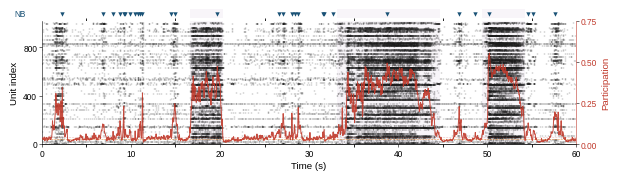

Saved: /pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M07420/Network/000052/well000/M07420_well000_raster.svg / .pdf


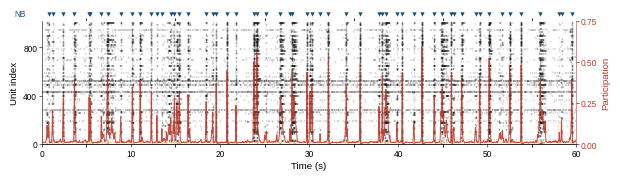

Saved: /pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M07420/Network/000052/well003/M07420_well003_raster.svg / .pdf


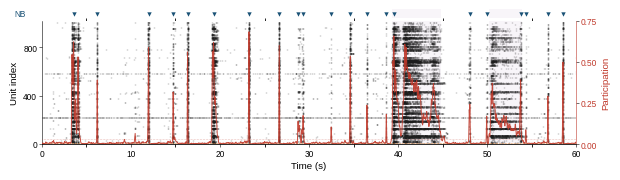

(<Figure size 685x180 with 3 Axes>,
 (<Axes: ylabel='NB'>,
  <Axes: xlabel='Time (s)', ylabel='Unit index'>,
  <Axes: ylabel='Participation'>))

In [11]:
# ── Dataset 1 ──
plot_raster_network(
    spike_times_path       = "/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M08018/Network/000058/well000/spike_times.npy",
    network_plot_data_path = "/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M08018/Network/000058/well000/network_plot_data.npz",
    output_prefix          = "/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M08018/Network/000058/well000/M08018_well000_raster",
    xmin=0, xmax=60,
)

# ── Dataset 2 ──
plot_raster_network(
    spike_times_path       = "/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M07420/Network/000052/well000/spike_times.npy",
    network_plot_data_path = "/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M07420/Network/000052/well000/network_plot_data.npz",
    output_prefix          = "/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M07420/Network/000052/well000/M07420_well000_raster",
    xmin=0, xmax=60,
)

# ── Dataset 3 ──
plot_raster_network(
    spike_times_path       = "/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M07420/Network/000052/well003/spike_times.npy",
    network_plot_data_path = "/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M07420/Network/000052/well003/network_plot_data.npz",
    output_prefix          = "/pscratch/sd/m/mpatil1/MEA_Analysis/AnalyzedData/V1_PYTHON/CDKL5_T1/240531/M07420/Network/000052/well003/M07420_well003_raster",
    xmin=0, xmax=60,
)

In [ ]:
#SEPARATE PLOT FOR PUBLICATION
fig, axs = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
ax_raster , ax_network = axs
#maximum time in spiketimes.values() is 300
spike_counts = {unit: len(times) for unit, times in spiketimes.items()}
sorted_units = sorted(spike_counts, key=spike_counts.get)
helper_functions.plot_clean_raster(
            ax_raster,
            spiketimes,
            sorted_units=sorted_units,
    color='#6E6E6E',
    markersize=4,
    markeredgewidth=0.5,
    alpha=0.3
    )
helper_functions.plot_clean_network(    ax_network,
   
    network_data["plot_data"]["t"],
    network_data["plot_data"]["signal"],
    threshold=network_data["plot_data"]["threshold"],
    color="#B22222")

nb_events = network_data["network_bursts"]["events"]
burst_intervals = [
    (ev["start"], ev["end"]) for ev in nb_events
]
for start, end in burst_intervals:
    ax_network.axvspan(start, end, color="#E78EA2", alpha=0.18)

#ax_raster.set_xlim(0, 60)
#ax_network.set_xlim(0,60)
ax_network.set_ylim(0,65)


fig.savefig(f"{RESULT_DIR}/M08018_well003_Healthy_seperateraster_network", dpi=300, bbox_inches='tight', format='svg')

In [ ]:
RESULT_DIR = "/mnt/Vol20tb1/user_workspaces/shruti/MEA_Analysis/MEA_Analysis_V2/MEA_Analysis/AnalyzedData/JGA_CSB3_010825_VD/250122/M08020/Network/000024/well005/"

spiketimes = np.load(f"{RESULT_DIR}/spike_times.npy", allow_pickle=True).item()

with open(f"{RESULT_DIR}/network_results.json", "r") as f:
    network_data = json.load(f)



In [ ]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots(figsize=(10, 4))
ax_raster = ax
ax_network = ax.twinx()
#sort spiketimes by firing rate (len /time)
#maximum time in spiketimes.values() is 300
timespan = max([(spiketimes[ch][-1]) for ch in spiketimes.keys()])
sorted_channels = sorted(spiketimes.keys(), key=lambda ch: len(spiketimes[ch])/timespan,reverse=True)
#sorted_channels = sorted(spiketimes.keys(), key=lambda ch: len(spiketimes[ch]))
# Raster (left axis)
helper_functions.plot_clean_raster(
    ax_raster,
    spiketimes,
    sorted_units=sorted_channels,
    color='#6E6E6E',
    markersize=4,
    markeredgewidth=0.5,
    alpha=0.4
)

# Network (right axis)
helper_functions.plot_clean_network(
    ax_network,
   
    network_data["plot_data"]["t"],
    network_data["plot_data"]["signal"],
    threshold=network_data["plot_data"]["threshold"],
    color="#B22222"

)
ax.spines["right"].set_visible(True)
#ax.set_xlim(0, 60)
ax_network.set_ylim(0,65)

fig.savefig(f"{RESULT_DIR}/M08020_E198K_well005_mergedraster", dpi=300, bbox_inches='tight', format='svg')


In [ ]:
#SEPARATE PLOT FOR PUBLICATION
fig, axs = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
ax_raster , ax_network = axs
#maximum time in spiketimes.values() is 300
spike_counts = {unit: len(times) for unit, times in spiketimes.items()}
sorted_units = sorted(spike_counts, key=spike_counts.get)
helper_functions.plot_clean_raster(
            ax_raster,
            spiketimes,
            sorted_units=sorted_units,
    color='#6E6E6E',
    markersize=4,
    markeredgewidth=0.5,
    alpha=0.3
    )
helper_functions.plot_clean_network(    ax_network,
   
    network_data["plot_data"]["t"],
    network_data["plot_data"]["signal"],
    threshold=network_data["plot_data"]["threshold"],
    color="#B22222")

nb_events = network_data["network_bursts"]["events"]
burst_intervals = [
    (ev["start"], ev["end"]) for ev in nb_events
]
for start, end in burst_intervals:
    ax_network.axvspan(start, end, color="#E78EA2", alpha=0.18)
ax_network.set_ylim(0,65)
#ax_raster.set_xlim(0, 60)
#ax_network.set_xlim(0,60)

fig.savefig(f"{RESULT_DIR}//M08020_E198K_well005_seperateraster_network", dpi=300, bbox_inches='tight', format='svg')

In [ ]:
RESULT_DIR = "/mnt/Vol20tb1/user_workspaces/shruti/MEA_Analysis/MEA_Analysis_V2/MEA_Analysis/AnalyzedData/JGA_CSB3_010825_VD/250122/M05506/Network/000028/well003/"

spiketimes = np.load(f"{RESULT_DIR}/spike_times.npy", allow_pickle=True).item()

with open(f"{RESULT_DIR}/network_results.json", "r") as f:
    network_data = json.load(f)



In [ ]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots(figsize=(10, 4))
ax_raster = ax
ax_network = ax.twinx()
#sort spiketimes by firing rate (len /time)
#maximum time in spiketimes.values() is 300
timespan = max([(spiketimes[ch][-1]) for ch in spiketimes.keys()])
sorted_channels = sorted(spiketimes.keys(), key=lambda ch: len(spiketimes[ch])/timespan,reverse=True)
#sorted_channels = sorted(spiketimes.keys(), key=lambda ch: len(spiketimes[ch]))
# Raster (left axis)
helper_functions.plot_clean_raster(
    ax_raster,
    spiketimes,
    sorted_units=sorted_channels,
    color='#6E6E6E',
    markersize=4,
    markeredgewidth=0.5,
    alpha=0.4
)

# Network (right axis)
helper_functions.plot_clean_network(
    ax_network,
   
    network_data["plot_data"]["t"],
    network_data["plot_data"]["signal"],
    threshold=network_data["plot_data"]["threshold"],
    color="#B22222"

)
ax.spines["right"].set_visible(True)
#ax.set_xlim(0, 60)
ax_network.set_ylim(0,65)

fig.savefig(f"{RESULT_DIR}/M05506_well003_E200k_mergedraster", dpi=300, bbox_inches='tight', format='svg')


In [ ]:
#SEPARATE PLOT FOR PUBLICATION
fig, axs = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
ax_raster , ax_network = axs
#maximum time in spiketimes.values() is 300
spike_counts = {unit: len(times) for unit, times in spiketimes.items()}
sorted_units = sorted(spike_counts, key=spike_counts.get)
helper_functions.plot_clean_raster(
            ax_raster,
            spiketimes,
            sorted_units=sorted_units,
    color='#6E6E6E',
    markersize=4,
    markeredgewidth=0.5,
    alpha=0.3
    )
helper_functions.plot_clean_network(    ax_network,
   
    network_data["plot_data"]["t"],
    network_data["plot_data"]["signal"],
    threshold=network_data["plot_data"]["threshold"],
    color="#B22222")

nb_events = network_data["network_bursts"]["events"]
burst_intervals = [
    (ev["start"], ev["end"]) for ev in nb_events
]
for start, end in burst_intervals:
    ax_network.axvspan(start, end, color="#E78EA2", alpha=0.18)

ax_network.set_ylim(0,65)
#ax_raster.set_xlim(0, 60)
#ax_network.set_xlim(0,60)

fig.savefig(f"{RESULT_DIR}/M05506_well003_E200k_seperateraster_network", dpi=300, bbox_inches='tight', format='svg')